# Double descent — book graphics 6b: bias–variance breakdown across the interpolation threshold

A 2 × 10 grid: for each polynomial degree 1…10, **top** all fits in the ensemble (thin), **bottom** the mean fit ± 1 std band, with the ensemble's bias² and variance printed under each column.

Every degree uses the same setup: `N_DATASETS` datasets of 10 points (5 training), seeds 0…N−1, noise σ = 0.2 on $f(x) = \tfrac12 x^2$, minimum-norm (pseudoinverse) Legendre fit. The interpolation threshold is degree 4 (5 parameters), where the bias–variance picture breaks down: with 5 points the variance explodes by orders of magnitude.

bias² = mean over x of $(f - \bar f)^2$; variance = mean over x and datasets of $(\hat f_D - \bar f)^2$; both over $x \in [-2, 2]$.

Exports: `grid_bias_variance_deg1-10.svg` (the whole figure, labels as editable text) plus the individual panels `all_fits_deg{d}.svg` / `mean_std_deg{d}.svg`.


## 1. Config

In [1]:
from pathlib import Path
import numpy as np
import scipy.special
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ── Book palette ───────────────────────────────────────────────────────────
CHILL_BROWN = '#948979'
LT_BLUE     = '#5badb6'
ORANGE      = '#eb8423'
GREEN       = '#419c52'
BLUE        = '#236c94'
RED         = '#d73b2f'
PINK        = '#ed5e78'
YELLOW      = '#fcc947'
LT_PURPLE   = '#b2c2e4'
PURPLE      = '#7e5b76'

AXIS_COLOR  = CHILL_BROWN
CURVE_COLOR = CHILL_BROWN
TEXT_COLOR  = CHILL_BROWN
DEGREES     = list(range(1, 11)) + [15, 20, 25, 50, 100]
FIT_COLORS  = {1: GREEN, 2: BLUE, 3: RED, 4: PINK, 5: PURPLE, 6: ORANGE, 7: LT_BLUE, 8: YELLOW,   # up to the peak...
               9: LT_BLUE, 10: ORANGE, 15: PURPLE, 20: PINK, 25: RED, 50: BLUE, 100: GREEN}         # ...and back down
DEFAULT_FIT_COLOR = BLUE          # for degrees not listed in FIT_COLORS
STD_ALPHA      = 0.2
ALL_FITS_ALPHA = 0.4

# ── Data / ensembles ───────────────────────────────────────────────────────
NOISE_LEVEL = 0.2
X_MIN, X_MAX = -2.0, 2.0
def f(x): return 0.5 * x**2
N_POINTS    = 10                 # per dataset; first N_TRAIN are the training points
N_TRAIN     = 5
N_DATASETS  = 256                # seeds 0 .. N_DATASETS-1

# ── Grid layout ────────────────────────────────────────────────────────────
ROW_ORDER    = ['all_fits', 'mean_std']   # top to bottom, within each degree's pair of rows
GRID_COLS    = 5                 # degrees per block; each block = len(ROW_ORDER) rows + labels
BLOCK_GAP_IN = 0.25 #0.55              # vertical gap between blocks (below one block's labels, above the next block's titles)
CELL_IN      = (1.6, 1.4)        # axes box per cell, inches
GAP_IN       = (0.3, 0.35)       # horizontal / vertical gap between cells
MARGIN_IN    = 0.6
LABEL_GAP_IN = 0.32              # space between the bottom row (incl. its tick labels) and the bias/variance text
LABEL_LINES  = ['bias2', 'variance']   # any of 'bias2', 'variance', 'sigma2', 'total', 'median_var'
LABEL_FMT    = '{name} = {value}'
LABEL_NAMES  = {'bias2': 'bias$^2$', 'variance': 'variance', 'sigma2': '$\\sigma^2$', 'total': 'total', 'median_var': 'median var'}
LABEL_FONTSIZE = 14
TITLE_LINES  = True              # 'degree d' above each column
TICK_LABELS  = 'edges'           # 'edges' (left column + bottom row), 'all', 'none'
GRID_FONTSIZE = 9

# ── Styling ────────────────────────────────────────────────────────────────
LINEWIDTH          = 1.5         # mean line and underlying curve
ALL_FITS_LINEWIDTH = 0.5
AXIS_LINEWIDTH     = 1.0
XLIM         = (X_MIN, X_MAX)
YLIM         = (-0.5, 2.0)
X_TICK_STEP  = 1.0
Y_TICK_STEP  = 1.0
SPINES       = 'lb'
CURVE_ALPHA  = 0.5
SHOW_MEAN_LINE = True
TRANSPARENT  = True

def fmt_value(v):
    """compact number formatting for the labels: plain below 1000, otherwise 10^k with one decimal."""
    if v < 1e-3:  return f'{v:.1e}'.replace('e-0', 'e-')
    if v < 1000:  return f'{v:.3f}' if v < 10 else f'{v:.1f}'
    e = int(np.floor(np.log10(v))); m = v / 10**e
    return f'${m:.1f}\\times 10^{{{e}}}$'

# ── Fonts: LaTeX / Computer Modern look ────────────────────────────────────
USE_TEX = True
plt.rcParams['font.family']  = 'serif'
plt.rcParams['font.serif']   = ['cmr10', 'Computer Modern Roman', 'DejaVu Serif']
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['axes.formatter.use_mathtext'] = True
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['text.usetex']  = USE_TEX
plt.rcParams['svg.fonttype'] = 'none'

# ── Output ─────────────────────────────────────────────────────────────────
OUT_DIR = Path('/Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/bias_variance_grid')
SAVE    = True
OUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. Helpers + ensembles

In [2]:
def legendre_features(x, degree, x_min=X_MIN, x_max=X_MAX):
    x_scaled = 2 * (x - x_min) / (x_max - x_min) - 1
    return scipy.special.eval_legendre(np.arange(degree + 1)[:, None], x_scaled).T

def fit_legendre_pinv(x_train, y_train, degree):
    return np.linalg.pinv(legendre_features(x_train, degree)) @ y_train

def eval_legendre_poly(beta, x, degree):
    return legendre_features(x, degree) @ beta

def get_noisy_data(n_points=N_POINTS, noise_level=NOISE_LEVEL, random_seed=0):
    np.random.seed(random_seed)
    x = np.random.uniform(X_MIN, X_MAX, n_points)
    y = f(x) + noise_level * np.random.randn(n_points)
    return x, y

all_x = np.linspace(X_MIN, X_MAX, 128)
all_y = f(all_x)
sigma2 = NOISE_LEVEL**2

datasets = []
for seed in range(N_DATASETS):
    x, y = get_noisy_data(random_seed=seed)
    datasets.append((x[:N_TRAIN], y[:N_TRAIN]))

ens = {}
for d in DEGREES:
    fits = np.array([eval_legendre_poly(fit_legendre_pinv(x_tr, y_tr, d), all_x, d) for x_tr, y_tr in datasets])
    mean_fit = fits.mean(0); std_fit = fits.std(0)
    per_ds = np.mean((fits - mean_fit)**2, axis=1)
    ens[d] = dict(fits=fits, mean=mean_fit, std=std_fit,
                  bias2=np.mean((all_y - mean_fit)**2), variance=per_ds.mean(), sigma2=sigma2,
                  median_var=np.median(per_ds))
    ens[d]['total'] = ens[d]['bias2'] + ens[d]['variance'] + sigma2

print(f'{N_DATASETS} datasets x {N_TRAIN} training points; interpolation threshold = degree {N_TRAIN - 1}')
print(f"{'deg':>3} {'bias^2':>12} {'variance':>14} {'total':>14} {'median ds var':>14}")
for d in DEGREES:
    e = ens[d]
    print(f"{d:>3} {e['bias2']:>12.4g} {e['variance']:>14.4g} {e['total']:>14.4g} {e['median_var']:>14.4g}")


256 datasets x 5 training points; interpolation threshold = degree 4
deg       bias^2       variance          total  median ds var
  1       0.4213         0.4541         0.9154         0.2056
  2      0.02051          11.88          11.94         0.0615
  3         1.11          391.8          392.9          1.393
  4    6.274e+06      1.657e+09      1.664e+09      6.275e+06
  5    6.897e+04      1.817e+07      1.824e+07        6.9e+04
  6         2373      6.419e+05      6.443e+05           2386
  7        200.9      5.955e+04      5.975e+04          207.6
  8        79.79      2.501e+04      2.509e+04          84.57
  9        63.97      2.053e+04       2.06e+04          67.81
 10        18.37           5884           5902          19.55
 15       0.8009            220          220.8          1.028
 20       0.2469          36.38          36.67         0.2513
 25       0.2256          10.75          11.01         0.1189
 50       0.2785         0.4366         0.7552        0.07278
1

## 3. Renderers

In [3]:
def style_ax(ax, color=AXIS_COLOR, fontsize=GRID_FONTSIZE):
    if SPINES == 'lb':
        ax.spines[['top', 'right']].set_visible(False)
    ax.spines[:].set_color(color)
    ax.spines[:].set_linewidth(AXIS_LINEWIDTH)
    ax.tick_params(colors=color, labelsize=fontsize, width=AXIS_LINEWIDTH, which='both')

def draw_panel(ax, d, kind, show_xlabels=True, show_ylabels=True, fontsize=GRID_FONTSIZE):
    e = ens[d]; col = FIT_COLORS.get(d, DEFAULT_FIT_COLOR)
    ax.plot(all_x, all_y, color=CURVE_COLOR, lw=LINEWIDTH, alpha=CURVE_ALPHA, zorder=3, solid_capstyle='round')
    if kind == 'all_fits':
        for c in e['fits']:
            ax.plot(all_x, c, color=col, lw=ALL_FITS_LINEWIDTH, alpha=ALL_FITS_ALPHA, zorder=2)
    else:
        ax.fill_between(all_x, e['mean'] - e['std'], e['mean'] + e['std'], color=col, alpha=STD_ALPHA, lw=0, zorder=1)
        if SHOW_MEAN_LINE:
            ax.plot(all_x, e['mean'], color=col, lw=LINEWIDTH, zorder=4, solid_capstyle='round')
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    ax.xaxis.set_major_locator(MultipleLocator(X_TICK_STEP))
    ax.yaxis.set_major_locator(MultipleLocator(Y_TICK_STEP))
    style_ax(ax, fontsize=fontsize)
    ax.tick_params(labelbottom=show_xlabels, labelleft=show_ylabels)

def label_text(d):
    e = ens[d]
    return '\n'.join(LABEL_FMT.format(name=LABEL_NAMES[k], value=fmt_value(e[k])) for k in LABEL_LINES)

def grid_figure():
    cw, ch = CELL_IN; gx, gy = GAP_IN
    n_rows = len(ROW_ORDER)
    blocks = [DEGREES[i:i + GRID_COLS] for i in range(0, len(DEGREES), GRID_COLS)]
    label_h = (0.16 * LABEL_FONTSIZE / 8) * len(LABEL_LINES) + LABEL_GAP_IN if LABEL_LINES else 0
    title_h = 0.25 if TITLE_LINES else 0
    block_h = title_h + n_rows * ch + (n_rows - 1) * gy + label_h
    W = 2 * MARGIN_IN + GRID_COLS * cw + (GRID_COLS - 1) * gx
    H = 2 * MARGIN_IN + len(blocks) * block_h + (len(blocks) - 1) * BLOCK_GAP_IN
    fig = plt.figure(figsize=(W, H))
    for b, block in enumerate(blocks):
        block_top = H - MARGIN_IN - b * (block_h + BLOCK_GAP_IN)
        for c, d in enumerate(block):
            x0 = MARGIN_IN + c * (cw + gx)
            for r, kind in enumerate(ROW_ORDER):
                y0 = block_top - title_h - ch - r * (ch + gy)
                ax = fig.add_axes([x0 / W, y0 / H, cw / W, ch / H])
                show_x = (r == n_rows - 1) if TICK_LABELS == 'edges' else TICK_LABELS == 'all'
                show_y = (c == 0) if TICK_LABELS == 'edges' else TICK_LABELS == 'all'
                draw_panel(ax, d, kind, show_x, show_y)
                if r == 0 and TITLE_LINES:
                    ax.set_title(f'degree {d}', color=TEXT_COLOR, fontsize=LABEL_FONTSIZE, pad=4)
            if LABEL_LINES:
                y_text = (block_top - block_h + label_h - LABEL_GAP_IN) / H
                fig.text((x0 + cw / 2) / W, y_text, label_text(d), ha='center', va='top',
                         color=TEXT_COLOR, fontsize=LABEL_FONTSIZE, linespacing=1.4)
    return fig

def panel_figure(d, kind):
    cw, ch = CELL_IN
    fig = plt.figure(figsize=(cw + 2 * MARGIN_IN, ch + 2 * MARGIN_IN))
    ax = fig.add_axes([MARGIN_IN / fig.get_figwidth(), MARGIN_IN / fig.get_figheight(),
                       cw / fig.get_figwidth(), ch / fig.get_figheight()])
    draw_panel(ax, d, kind)
    return fig, ax


## 4. Preview

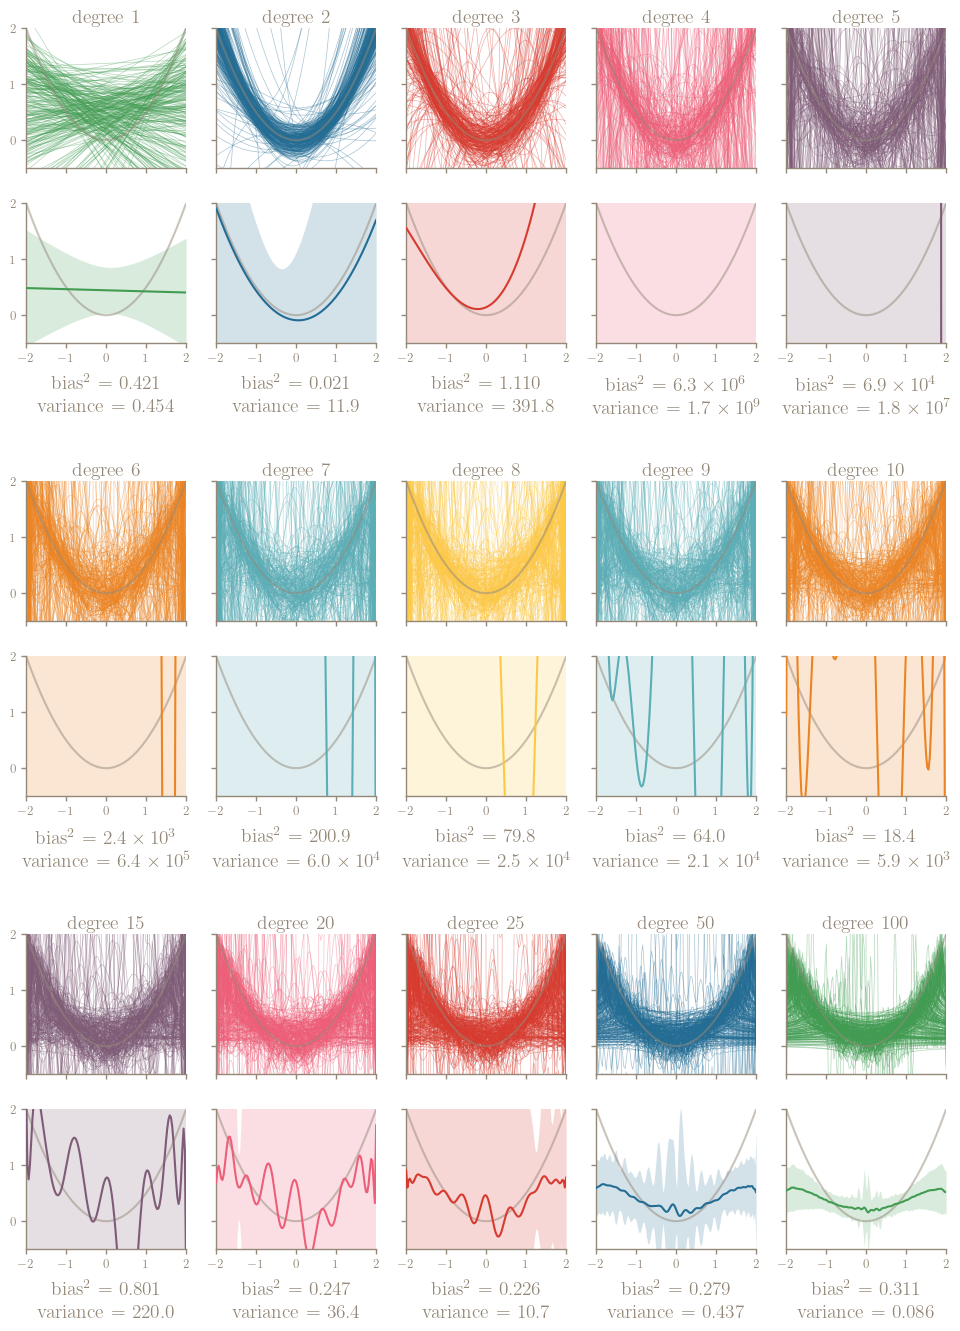

In [4]:
fig = grid_figure(); plt.show()


## 5. Export

In [5]:
def save(fig, stem):
    for ext in ('svg', 'png'):
        fig.savefig(OUT_DIR / f'{stem}.{ext}', dpi=300, transparent=TRANSPARENT, bbox_inches='tight')
    plt.close(fig)

if SAVE:
    save(grid_figure(), f'grid_bias_variance_deg{DEGREES[0]}-{DEGREES[-1]}')
    for d in DEGREES:
        for kind in ROW_ORDER:
            fig, _ = panel_figure(d, kind); save(fig, f'{kind}_deg{d}')
    print('saved to', OUT_DIR)
    for p in sorted(OUT_DIR.glob('*.svg')):
        print('  ', p.name)


saved to /Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/bias_variance_grid
   all_fits_deg1.svg
   all_fits_deg10.svg
   all_fits_deg100.svg
   all_fits_deg15.svg
   all_fits_deg2.svg
   all_fits_deg20.svg
   all_fits_deg25.svg
   all_fits_deg3.svg
   all_fits_deg4.svg
   all_fits_deg5.svg
   all_fits_deg50.svg
   all_fits_deg6.svg
   all_fits_deg7.svg
   all_fits_deg8.svg
   all_fits_deg9.svg
   grid_bias_variance_deg1-100.svg
   mean_std_deg1.svg
   mean_std_deg10.svg
   mean_std_deg100.svg
   mean_std_deg15.svg
   mean_std_deg2.svg
   mean_std_deg20.svg
   mean_std_deg25.svg
   mean_std_deg3.svg
   mean_std_deg4.svg
   mean_std_deg5.svg
   mean_std_deg50.svg
   mean_std_deg6.svg
   mean_std_deg7.svg
   mean_std_deg8.svg
   mean_std_deg9.svg
